# SNAIL JTWPA — Parameter Design and Pre-Julia Validation

This notebook is the **parameter-design stage** of a 3-wave-mixing SNAIL JTWPA.

The workflow is:

1. SNAIL static potential and stability.
2. Select `(n, alpha, Phi_ext/Phi0)` using the cubic coefficient and bare Kerr-free condition.
3. Map the dimensionless SNAIL to physical junction `Ic`, `Lj`, area and capacitance.
4. Design the RF transmission-line impedance with an explicit shunt capacitor.
5. Compute the **exact discrete Bloch dispersion**.
6. Check cold 3WM phase mismatch.
7. Estimate pump-current and phase-amplitude limits.
8. Check finite SNAIL loop inductance.
9. Export a compact parameter handoff for Julia.

The baseline architecture is a **DC-flux-biased SNAIL JTWPA**: the microwave
pump propagates through the same nonlinear line as the signal. A separate
RF flux-pump architecture is intentionally not used in the baseline.

## Modeling conventions

For the ideal `n`-large-junction / one-small-junction SNAIL,

\[
u(\phi)=-n\cos(\phi/n)-\alpha\cos(\phi_\mathrm{ext}-\phi),
\]

where `phi` is the phase coordinate of the large-junction arm and

\[
\phi_s=\phi_\mathrm{ext}-\phi
\]

is the small-junction phase.

At the stable minimum,

\[
c_2=u'',\qquad c_3=u''',\qquad c_4=u''''.
\]

The small-signal SNAIL inductance is

\[
L_\mathrm{SNAIL}=\frac{L_{J,L}}{c_2}.
\]

The first-pass design targets the **bare** `c4 ≈ 0` condition. A
cubic-induced effective-quartic diagnostic is also reported, but is not used
as the sole optimization target. Final phase matching must be determined from
the pumped nonlinear circuit.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq, root
from pathlib import Path
import json

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

Phi0 = 2.0678338484619295e-15
phi0 = Phi0/(2*np.pi)

# ---------------------------
# User design requirements
# ---------------------------
n = 3
alpha_nominal = 0.29
flux_nominal = None

Z0_target = 50.0
Lcell_target = 145e-12
Csh_target = Lcell_target/Z0_target**2

# Replace these with the actual process/PDK values.
Jc = 1.0e7                         # A/m^2 = 1 kA/cm^2
Cj_areal = 45e-15/1e-12           # F/m^2 = 45 fF/um^2

fp = 12e9
fs_min, fs_max = 4e9, 8e9
N_cells = 600

# Small geometric loop inductance for the bias implementation.
Lloop = 0.74e-12

print(f"RF shunt C = {Csh_target*1e15:.3f} fF")

RF shunt C = 58.000 fF


In [2]:
def snail_roots(n, alpha, phi_ext, points=6001):
    x = np.linspace(-n*np.pi, n*np.pi, points)
    y = np.sin(x/n) - alpha*np.sin(phi_ext-x)
    roots = []
    for i in range(len(x)-1):
        if y[i] == 0:
            roots.append(x[i])
        elif y[i]*y[i+1] < 0:
            roots.append(brentq(
                lambda p: np.sin(p/n)-alpha*np.sin(phi_ext-p),
                x[i], x[i+1]
            ))
    out = []
    for r in roots:
        if not out or abs(r-out[-1]) > 1e-7:
            out.append(r)
    return out


def snail_coefficients(n, alpha, phi_ext):
    # u(phi) = -n cos(phi/n) - alpha cos(phi_ext-phi)
    candidates = []
    for p in snail_roots(n, alpha, phi_ext):
        u = -n*np.cos(p/n)-alpha*np.cos(phi_ext-p)
        c2 = np.cos(p/n)/n + alpha*np.cos(phi_ext-p)
        c3 = -np.sin(p/n)/n**2 + alpha*np.sin(phi_ext-p)
        c4 = -np.cos(p/n)/n**3 - alpha*np.cos(phi_ext-p)
        if c2 > 0:
            candidates.append((u,p,c2,c3,c4))
    if not candidates:
        return None
    return min(candidates, key=lambda x:x[0])


def effective_quartic_diagnostic(c2,c3,c4):
    return c4 - (5.0/3.0)*(c3**2/c2)

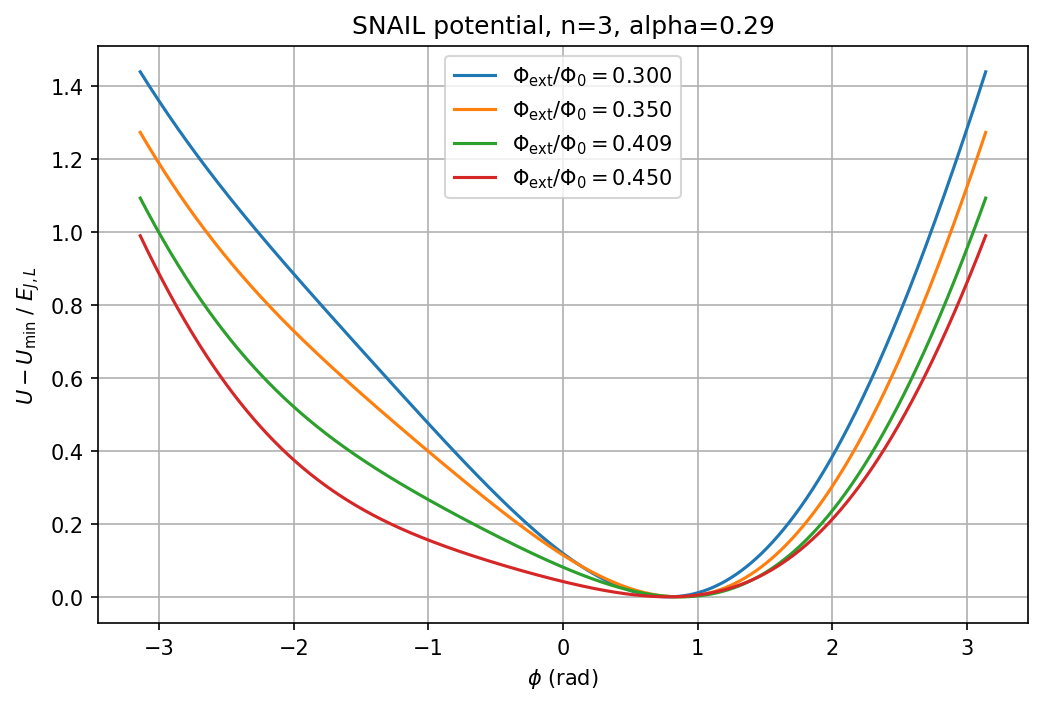

In [3]:
fluxes = [0.30, 0.35, 0.409, 0.45]
phi = np.linspace(-np.pi, np.pi, 2000)

fig, ax = plt.subplots()
for f in fluxes:
    u = -n*np.cos(phi/n)-alpha_nominal*np.cos(2*np.pi*f-phi)
    u -= u.min()
    ax.plot(phi, u, label=fr"$\Phi_\mathrm{{ext}}/\Phi_0={f:.3f}$")
ax.set_xlabel(r"$\phi$ (rad)")
ax.set_ylabel(r"$U-U_{\min}$ / $E_{J,L}$")
ax.set_title(f"SNAIL potential, n={n}, alpha={alpha_nominal}")
ax.legend()
plt.show()

## 1. Scan `(alpha, flux)` for the bare Kerr-free point

For each `alpha`, search for a stable point where `c4 ≈ 0`, while retaining
`c2 > 0` and avoiding an unnecessarily aggressive bias near `0.5 Phi0`.

    alpha      flux        c2  ...  c3_over_c2  c4_eff_diagnostic   phi_min
0   0.200  0.373581  0.290509  ...    0.601781          -0.175342  0.593899
1   0.205  0.375314  0.290203  ...    0.618005          -0.184728  0.609479
2   0.210  0.377083  0.289888  ...    0.634268          -0.194368  0.625063
3   0.215  0.378885  0.289566  ...    0.650572          -0.204262  0.640652
4   0.220  0.380720  0.289235  ...    0.666920          -0.214411  0.656248
5   0.225  0.382584  0.288897  ...    0.683313          -0.224818  0.671851
6   0.230  0.384476  0.288551  ...    0.699755          -0.235485  0.687464
7   0.235  0.386394  0.288196  ...    0.716247          -0.246413  0.703086
8   0.240  0.388337  0.287834  ...    0.732792          -0.257604  0.718719
9   0.245  0.390305  0.287463  ...    0.749392          -0.269060  0.734364
10  0.250  0.392294  0.287085  ...    0.766049          -0.280784  0.750022
11  0.255  0.394306  0.286698  ...    0.782765          -0.292776  0.765694
12  0.260  0

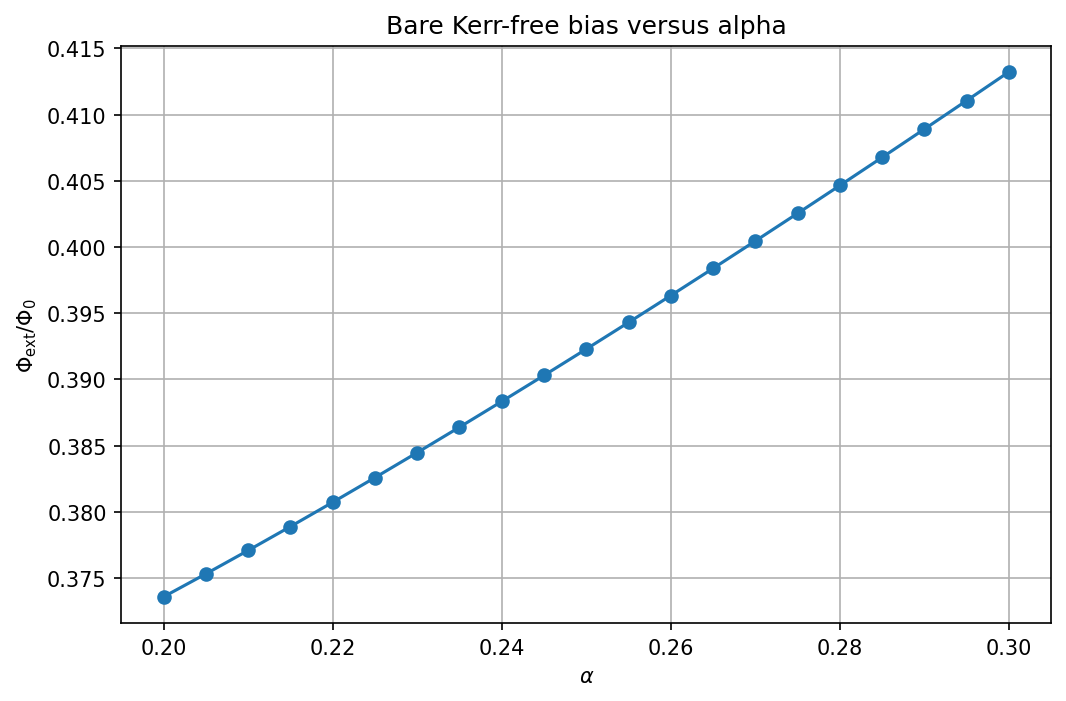

In [4]:
def find_c4_zero_for_alpha(alpha, fmin=0.30, fmax=0.45, npts=600):
    fs = np.linspace(fmin, fmax, npts)
    vals = []
    for f in fs:
        q = snail_coefficients(n, alpha, 2*np.pi*f)
        vals.append(np.nan if q is None else q[4])

    roots = []
    for i in range(len(fs)-1):
        if np.isfinite(vals[i]) and np.isfinite(vals[i+1]) and vals[i]*vals[i+1] < 0:
            roots.append(brentq(
                lambda ff: snail_coefficients(n, alpha, 2*np.pi*ff)[4],
                fs[i], fs[i+1]
            ))
    return roots


rows = []
for a in np.linspace(0.20,0.30,21):
    for f in find_c4_zero_for_alpha(a):
        q = snail_coefficients(n,a,2*np.pi*f)
        if q is None:
            continue
        u,pmin,c2a,c3a,c4a = q
        rows.append({
            "alpha":a, "flux":f, "c2":c2a, "c3":c3a, "c4":c4a,
            "c3_over_c2":c3a/c2a,
            "c4_eff_diagnostic":effective_quartic_diagnostic(c2a,c3a,c4a),
            "phi_min":pmin
        })

candidates = pd.DataFrame(rows)
display(candidates)

fig, ax = plt.subplots()
ax.plot(candidates["alpha"], candidates["flux"], "o-")
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$\Phi_\mathrm{ext}/\Phi_0$")
ax.set_title("Bare Kerr-free bias versus alpha")
plt.show()

### Baseline candidate

We deliberately move away from the previous `alpha=0.33` point.

For

\[
n=3,\qquad \alpha=0.29
\]

the bare Kerr-free solution is approximately

\[
\boxed{\Phi_\mathrm{ext}/\Phi_0=0.4089}
\]

with

\[
c_2\approx0.28376,\quad c_3\approx0.25584,\quad c_4\approx0.
\]

This is a **baseline candidate**, not a tape-out value. The final flux must be
rechecked after finite loop inductance, actual junction parameters and EM
parasitics are included.

In [5]:
alpha_nominal = 0.29
flux_nominal = find_c4_zero_for_alpha(alpha_nominal)[0]
u_min, phi_min, c2, c3, c4 = snail_coefficients(
    n, alpha_nominal, 2*np.pi*flux_nominal
)

print(f"alpha = {alpha_nominal:.6f}")
print(f"Phi_ext/Phi0 = {flux_nominal:.9f}")
print(f"phi_min = {phi_min:.9f} rad")
print(f"c2 = {c2:.9f}")
print(f"c3 = {c3:.9f}")
print(f"c4 = {c4:.3e}")
print(f"effective-quartic diagnostic = {effective_quartic_diagnostic(c2,c3,c4):.6f}")

alpha = 0.290000
Phi_ext/Phi0 = 0.408912098
phi_min = 0.875857597 rad
c2 = 0.283758139
c3 = 0.255842383
c4 = 3.201e-13
effective-quartic diagnostic = -0.384455


## 2. Map the SNAIL to physical junction parameters

Choose the target RF small-signal cell inductance first:

\[
L_\mathrm{cell}=145\ {\rm pH}.
\]

Then

\[
L_{J,L}=c_2L_\mathrm{cell},
\qquad
I_{c,L}=\frac{\Phi_0}{2\pi L_{J,L}},
\qquad
I_{c,S}=\alpha I_{c,L}.
\]

The line's RF shunt capacitor is chosen independently:

\[
C_g=\frac{L_\mathrm{cell}}{Z_0^2}.
\]

The junction capacitances are parasitic/internal capacitances and should not be
mistaken for the line's intentional shunt capacitance.

In [6]:
LJ_large = c2*Lcell_target
Ic_large = phi0/LJ_large
Ic_small = alpha_nominal*Ic_large

A_large = Ic_large/Jc
A_small = Ic_small/Jc

Cj_large = Cj_areal*A_large
Cj_small = Cj_areal*A_small

# Crude terminal-capacitance estimate:
C_snaill_internal_est = Cj_large/3 + Cj_small

C_shunt = Csh_target

f_lc_scale = 1/(2*np.pi*np.sqrt(Lcell_target*C_shunt))
f_band_edge = 1/(np.pi*np.sqrt(Lcell_target*C_shunt))
f_internal_plasma_est = 1/(2*np.pi*np.sqrt(
    Lcell_target*C_snaill_internal_est
))

design = pd.Series({
    "n":n,
    "alpha":alpha_nominal,
    "Phi_ext/Phi0":flux_nominal,
    "c2":c2, "c3":c3, "c4":c4,
    "Z0_ohm":Z0_target,
    "Lcell_pH":Lcell_target*1e12,
    "Cshunt_fF":C_shunt*1e15,
    "Lj_large_pH":LJ_large*1e12,
    "Ic_large_uA":Ic_large*1e6,
    "Ic_small_uA":Ic_small*1e6,
    "A_large_um2":A_large*1e12,
    "A_small_um2":A_small*1e12,
    "Cj_large_fF":Cj_large*1e15,
    "Cj_small_fF":Cj_small*1e15,
    "C_snaill_internal_est_fF":C_snaill_internal_est*1e15,
    "f_lc_scale_GHz":f_lc_scale/1e9,
    "f_discrete_band_edge_GHz":f_band_edge/1e9,
    "f_internal_plasma_est_GHz":f_internal_plasma_est/1e9,
    "N_cells":N_cells,
    "pump_GHz":fp/1e9,
    "signal_min_GHz":fs_min/1e9,
    "signal_max_GHz":fs_max/1e9
})
display(design)

n                            3.000000e+00
alpha                        2.900000e-01
Phi_ext/Phi0                 4.089121e-01
c2                           2.837581e-01
c3                           2.558424e-01
c4                           3.201189e-13
Z0_ohm                       5.000000e+01
Lcell_pH                     1.450000e+02
Cshunt_fF                    5.800000e+01
Lj_large_pH                  4.114493e+01
Ic_large_uA                  7.998701e+00
Ic_small_uA                  2.319623e+00
A_large_um2                  7.998701e-01
A_small_um2                  2.319623e-01
Cj_large_fF                  3.599415e+01
Cj_small_fF                  1.043830e+01
C_snaill_internal_est_fF     2.243636e+01
f_lc_scale_GHz               5.488101e+01
f_discrete_band_edge_GHz     1.097620e+02
f_internal_plasma_est_GHz    8.823888e+01
N_cells                      6.000000e+02
pump_GHz                     1.200000e+01
signal_min_GHz               4.000000e+00
signal_max_GHz               8.000

## 3. Exact discrete Bloch dispersion

For the series-`L` / shunt-`C` ladder,

\[
\cos(k)=1-\frac{\omega^2LC}{2}.
\]

The quantity

\[
1/(2\pi\sqrt{LC})
\]

is only the LC frequency scale. The actual discrete band edge is

\[
f_\mathrm{edge}=1/(\pi\sqrt{LC}).
\]

This distinction matters when comparing the line to the pump and internal
junction plasma scales.

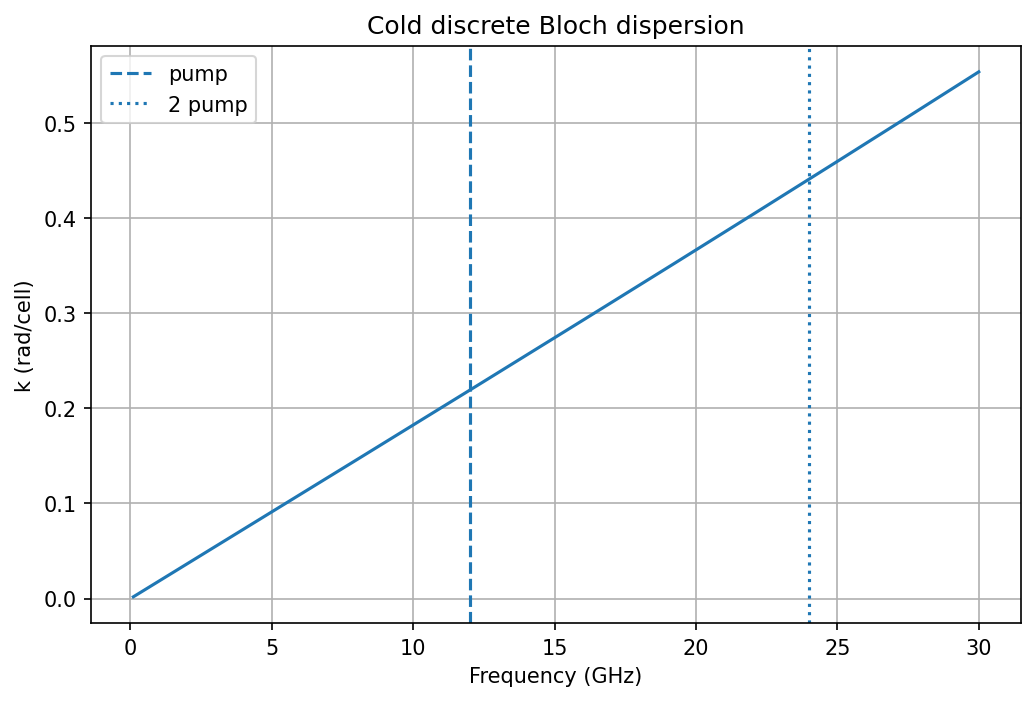

In [7]:
def bloch_k(f,L=Lcell_target,C=C_shunt):
    omega = 2*np.pi*np.asarray(f)
    arg = 1-(omega**2)*L*C/2
    out = np.full_like(arg,np.nan,dtype=float)
    mask = (arg >= -1) & (arg <= 1)
    out[mask] = np.arccos(arg[mask])
    return out

freqs = np.linspace(0.1e9,30e9,1000)
fig, ax = plt.subplots()
ax.plot(freqs/1e9,bloch_k(freqs))
ax.axvline(fp/1e9,ls="--",label="pump")
ax.axvline(2*fp/1e9,ls=":",label="2 pump")
ax.set_xlabel("Frequency (GHz)")
ax.set_ylabel("k (rad/cell)")
ax.set_title("Cold discrete Bloch dispersion")
ax.legend()
plt.show()

max |Delta k| = 0.00032889654653914246 rad/cell
max |N*Delta k| = 0.19733792792348548 rad over line


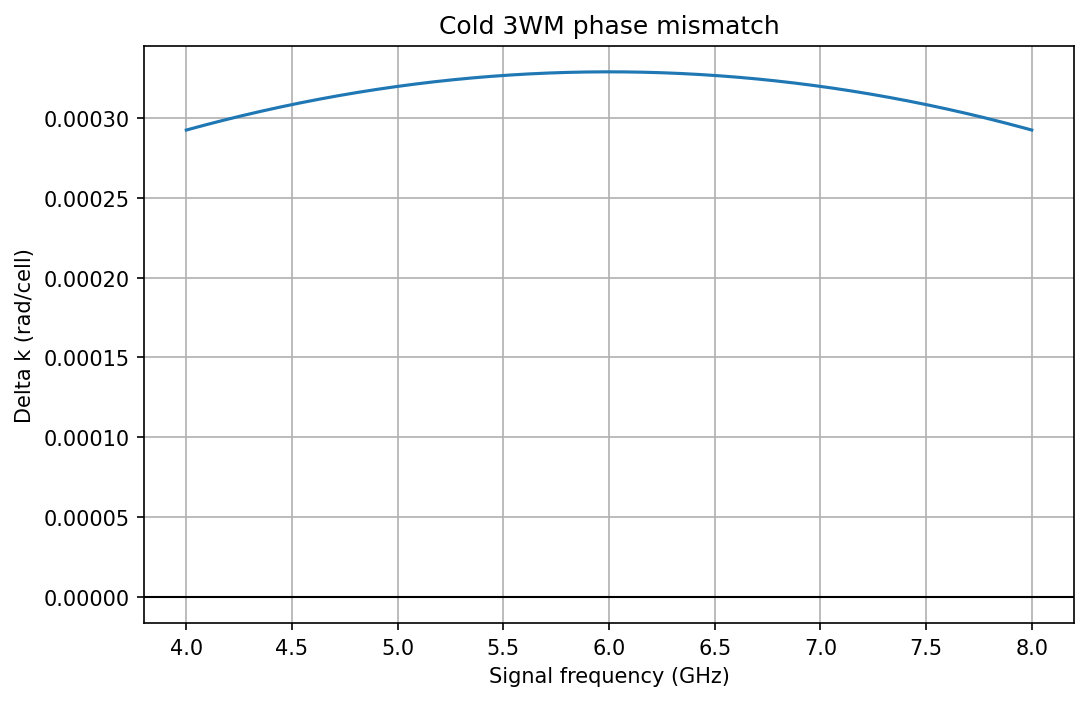

In [8]:
signal_freqs = np.linspace(fs_min,fs_max,401)
idler_freqs = fp-signal_freqs

kp = float(bloch_k(fp))
ks = bloch_k(signal_freqs)
ki = bloch_k(idler_freqs)
delta_k_cold = kp-ks-ki

fig, ax = plt.subplots()
ax.plot(signal_freqs/1e9,delta_k_cold)
ax.axhline(0,color="black",lw=1)
ax.set_xlabel("Signal frequency (GHz)")
ax.set_ylabel("Delta k (rad/cell)")
ax.set_title("Cold 3WM phase mismatch")
plt.show()

print("max |Delta k| =", np.nanmax(np.abs(delta_k_cold)), "rad/cell")
print("max |N*Delta k| =", N_cells*np.nanmax(np.abs(delta_k_cold)), "rad over line")

For this baseline line the cold mismatch is only of order `3e-4 rad/cell`.
That is encouraging, but it is **not** the final phase-matching criterion.

The actual quantity is

\[
\Delta k_\mathrm{total}
=
k_p-k_s-k_i+\Delta k_\mathrm{NL}(I_p),
\]

where the nonlinear pump-induced contribution must come from the pumped
JosephsonCircuits simulation.

## 4. Pump-current sanity checks

For a 50-ohm line,

\[
P=\frac{I_\mathrm{peak}^2Z_0}{2}.
\]

We sweep pump current as a fraction of `Ic` rather than guessing one pump
power. The final operating point must be chosen from gain, phase matching,
pump depletion and stability.

In [9]:
fractions = np.array([0.03,0.05,0.075,0.10,0.15,0.20,0.25,0.30])
Ip_peak = fractions*Ic_large
Ppump_W = Ip_peak**2*Z0_target/2
Ppump_dBm = 10*np.log10(Ppump_W/1e-3)

pump_table = pd.DataFrame({
    "Ip/Ic":fractions,
    "Ip_peak_uA":Ip_peak*1e6,
    "Ppump_dBm":Ppump_dBm,
    "phase_amplitude_est_rad":Ip_peak*Lcell_target/phi0
})
display(pump_table)

   Ip/Ic  Ip_peak_uA  Ppump_dBm  phase_amplitude_est_rad
0  0.030    0.239961 -88.417786                 0.105724
1  0.050    0.399935 -83.980811                 0.176206
2  0.075    0.599903 -80.458986                 0.264310
3  0.100    0.799870 -77.960211                 0.352413
4  0.150    1.199805 -74.438386                 0.528619
5  0.200    1.599740 -71.939611                 0.704826
6  0.250    1.999675 -70.001411                 0.881032
7  0.300    2.399610 -68.417786                 1.057238


## 5. Finite loop-inductance sensitivity

A real SNAIL has geometric loop inductance. We keep a small `Lloop` explicit
and check how much it perturbs the operating point.

This is a sensitivity calculation, not an EM replacement. The extracted
layout value must eventually be returned here.

In [10]:
def finite_loop_operating_point(n,alpha,flux_fraction,beta,initial=None):
    phi_ext = 2*np.pi*flux_fraction
    if initial is None:
        q0 = snail_coefficients(n,alpha,phi_ext)
        x0 = q0[1]
        g0 = beta*alpha*np.sin(phi_ext-x0)
    else:
        x0,g0 = initial

    def eq(v):
        x,g = v
        phi_s = phi_ext-x-g
        return [
            np.sin(x/n)-alpha*np.sin(phi_s),
            -alpha*np.sin(phi_s)+g/beta
        ]

    sol = root(eq,[x0,g0])
    if not sol.success:
        raise RuntimeError(sol.message)
    x,g = sol.x
    return x,g,phi_ext-x-g

beta_L = Lloop/LJ_large
xfin,gfin,phisfin = finite_loop_operating_point(
    n,alpha_nominal,flux_nominal,beta_L
)

print("Lloop/LJ_large =",beta_L)
print("finite-loop large-arm phase =",xfin)
print("finite-loop geometric phase =",gfin)
print("finite-loop small-JJ phase =",phisfin)

Lloop/LJ_large = 0.017985204928305402
finite-loop large-arm phase = 0.8764880127877147
finite-loop geometric phase = 0.0051801692424002285
finite-loop small-JJ phase = 1.6876023060157523


### Starting bias-coil numbers

The first physical bias implementation can use a mutual-inductance target

\[
M\sim5\ {\rm pH}
\]

as an engineering starting point. The required DC current is

\[
I_\mathrm{bias}\approx\frac{(\Phi_\mathrm{ext}/\Phi_0)\Phi_0}{M}.
\]

The mutual inductance and bias-line inductance must ultimately be obtained from
EM extraction.

In [11]:
M_bias = 5e-12
I_bias = flux_nominal*Phi0/M_bias

Lbias_example = 0.70e-9
K_required = M_bias/np.sqrt(Lloop*Lbias_example)

print(f"M_bias = {M_bias*1e12:.3f} pH")
print(f"I_bias = {I_bias*1e6:.2f} uA")
print(f"For Lbias={Lbias_example*1e9:.3f} nH, K={K_required:.3f}")

M_bias = 5.000 pH
I_bias = 169.11 uA
For Lbias=0.700 nH, K=0.220


## 6. Optional resonant phase matching

The baseline design deliberately contains **no periodic resonant phase-matching
network**.

Only add one if the pumped simulation shows that the nonlinear phase mismatch
is too large. If needed, optimize the resonator against the **pumped**
dispersion, not just the cold line.

This avoids introducing the previous 2`fp` stopband without demonstrating that
it fixes the 3WM momentum condition.

In [12]:
handoff = {
    "architecture":"DC-flux-biased SNAIL JTWPA, 3WM",
    "n_large_junctions":int(n),
    "alpha":float(alpha_nominal),
    "flux_ext_over_phi0":float(flux_nominal),
    "c2":float(c2), "c3":float(c3), "c4":float(c4),
    "Z0_ohm":float(Z0_target),
    "Lcell_H":float(Lcell_target),
    "Cshunt_F":float(C_shunt),
    "Lj_large_H":float(LJ_large),
    "Ic_large_A":float(Ic_large),
    "Ic_small_A":float(Ic_small),
    "junction_area_large_m2":float(A_large),
    "junction_area_small_m2":float(A_small),
    "Cj_large_F":float(Cj_large),
    "Cj_small_F":float(Cj_small),
    "Lloop_H":float(Lloop),
    "bias_mutual_start_H":float(M_bias),
    "bias_current_A":float(I_bias),
    "K_bias_start":float(K_required),
    "N_cells":int(N_cells),
    "pump_frequency_Hz":float(fp),
    "signal_min_Hz":float(fs_min),
    "signal_max_Hz":float(fs_max)
}

json_path = Path("snail_jtwpa_design_parameters.json")
json_path.write_text(json.dumps(handoff,indent=2))
print(json.dumps(handoff,indent=2))
print("Wrote:",json_path.resolve())

{
  "architecture": "DC-flux-biased SNAIL JTWPA, 3WM",
  "n_large_junctions": 3,
  "alpha": 0.29,
  "flux_ext_over_phi0": 0.40891209831262615,
  "c2": 0.2837581387705058,
  "c3": 0.25584238296649287,
  "c4": 3.2011893136285607e-13,
  "Z0_ohm": 50.0,
  "Lcell_H": 1.45e-10,
  "Cshunt_F": 5.799999999999999e-14,
  "Lj_large_H": 4.114493012172334e-11,
  "Ic_large_A": 7.998700629745263e-06,
  "Ic_small_A": 2.319623182626126e-06,
  "junction_area_large_m2": 7.998700629745263e-13,
  "junction_area_small_m2": 2.3196231826261263e-13,
  "Cj_large_F": 3.599415283385368e-14,
  "Cj_small_F": 1.0438304321817569e-14,
  "Lloop_H": 7.4e-13,
  "bias_mutual_start_H": 5e-12,
  "bias_current_A": 0.00016911245558728813,
  "K_bias_start": 0.2196873875818734,
  "N_cells": 600,
  "pump_frequency_Hz": 12000000000.0,
  "signal_min_Hz": 4000000000.0,
  "signal_max_Hz": 8000000000.0
}
Wrote: C:\Users\Mukul\Music\projects\research-profile\repos\snail-jtwpa-design\notebooks\snail_jtwpa_design_parameters.json


# Pre-Julia acceptance checklist

- [x] Stable SNAIL minimum with `c2 > 0`.
- [x] Strong cubic coefficient.
- [x] Bare `c4 ≈ 0`.
- [x] More conservative `alpha=0.29` baseline.
- [x] RF shunt capacitance separated from junction capacitance.
- [x] Exact discrete Bloch dispersion.
- [x] Cold 3WM mismatch calculated.
- [x] Pump current treated as a fraction of `Ic`.
- [x] Finite loop inductance tracked.
- [ ] Single-SNAIL JosephsonCircuits result reproduces the Python linearized inductance.
- [ ] 5–20-cell unpumped line reproduces the Python dispersion.
- [ ] 5–20-cell pumped 3WM converges.
- [ ] Pump-induced nonlinear phase mismatch is measured.
- [ ] Only then scale toward 300–600 cells.